# CAPSTONE LOS — Ridge and additional features

Five fixed Ridge(alpha=1) experiments: common inputs, +comorbidity, +monitoring,
+care team, and +all three. No SAS or dashboard changes. Run all cells in order.

Reuses the source-checked CAPSTONE snapshot and the same split as the existing
HistGB ablation (80,034 train / 10,006 validation / 9,960 test). All preprocessing
is fitted on training rows only. Model selection uses validation MAE; the previously
used test set is descriptive confirmation, not a new independent evaluation.

The target follows the existing experiment: TOTAL_LOS = ADMIT_LOS + ICU_DAYS.
Its clinical meaning and possible overlap of these durations need provider confirmation.
The three extra variables have unconfirmed availability and generation timing;
this is retrospective exploratory analysis, not a validated admission-time predictor.

Dependencies: pandas, numpy, scipy, scikit-learn, openpyxl, matplotlib, joblib,
threadpoolctl. Run from this project (Model folder or project root).


In [1]:
from pathlib import Path
import sys, json, platform
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
import joblib
from IPython.display import display
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from threadpoolctl import threadpool_limits

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p/'Model/los_three_feature_evidence.py').exists()), None)
if ROOT is None:
    raise RuntimeError('Open from the project root or Model folder.')
sys.path.insert(0, str(ROOT/'Model'))
import los_mae_optimisation as base
import los_three_feature_evidence as evidence
import importlib
# Refresh helper modules if this notebook was already open before an update.
importlib.reload(base)
importlib.reload(evidence)
from los_three_feature_evidence import load_external
ALPHA = 1.0  # fixed before looking at test results; no tuning in this notebook
FEATURE_SETS = {
    'Common only': [],
    '+ Comorbidity': ['COMORBIDITY_INDEX'],
    '+ Monitoring': ['MONITORING_HOURS'],
    '+ Care team': ['CARE_TEAM_SIZE'],
    '+ All three': ['COMORBIDITY_INDEX', 'MONITORING_HOURS', 'CARE_TEAM_SIZE']
}


## 1. Load and validate the fixed data and partitions

In [2]:
data, metadata, X, y, meta, prior_dir, prep_dir, baseline_manifest = load_external(ROOT, source_scope='capstone')
masks = {s: meta.SPLIT.eq(s) for s in ['Train','Validation','Test']}
assert [int(m.sum()) for m in masks.values()] == [80034,10006,9960]
assert X.index.equals(y.index) and X.index.equals(meta.index)
assert y.notna().all() and np.isfinite(y).all()
display(meta.groupby('SPLIT').size().rename('Rows').to_frame())
display(X[['COMORBIDITY_INDEX','MONITORING_HOURS','CARE_TEAM_SIZE']].isna().sum().rename('Missing values').to_frame())
print('CAPSTONE source, saved analysis snapshot and split hashes, encounter alignment and target checked.')
print('Historical source workbooks are not used in this CAPSTONE-only experiment.')


,Rows
SPLIT,
Test,9960
Train,80034
Validation,10006


,Missing values
COMORBIDITY_INDEX,0
MONITORING_HOURS,0
CARE_TEAM_SIZE,0


CAPSTONE source, saved analysis snapshot and split hashes, encounter alignment and target checked.
Historical source workbooks are not used in this CAPSTONE-only experiment.


## 2. Fixed Ridge pipeline

The common predictor definitions match the HistGB ablation, including derived
features and exclusion of DOCTOR / Patient location. Ridge uses one-hot encoding
and numeric scaling; HistGB used native categorical handling. This is appropriate
model-specific preprocessing, not identical numerical representations.
Within the five Ridge runs only the extra columns change. Raw predictions are not clipped.


In [3]:
NUMERIC = base.NUMERIC + ['LOG1P_VISITS','AGE_CENTRED_SQUARED','AGE_X_CHRONIC']
CATEGORICAL = [c for c in base.CATEGORICAL if c not in ['DOCTOR','Patient location']]
CATEGORICAL += ['ICD_FAMILY','CHRONIC_BAND']
def make_model(extras):
    pre = ColumnTransformer([
        ('numeric', Pipeline([('impute', SimpleImputer(strategy='median')),
                              ('scale', StandardScaler())]), NUMERIC + extras),
        ('categorical', OneHotEncoder(handle_unknown='ignore', sparse_output=True), CATEGORICAL)
    ], sparse_threshold=1.0)
    return Pipeline([
        ('features', FunctionTransformer(base.add_features, validate=False, kw_args={'kind':'reduced'})),
        ('preprocess', pre),
        ('model', Ridge(alpha=ALPHA, solver='lsqr', tol=1e-8))
    ])
def metrics(actual, pred):
    if not np.isfinite(pred).all():
        raise ValueError('Non-finite predictions; inspect the model before continuing.')
    return dict(MAE_days=float(mean_absolute_error(actual,pred)),
                RMSE_days=float(np.sqrt(mean_squared_error(actual,pred))),
                R2=float(r2_score(actual,pred)), negative_predictions=int((pred<0).sum()))


## 3. Train five models and select by validation MAE

In [4]:
models, validation_rows = {}, []
with threadpool_limits(limits=1):
    for name, extras in FEATURE_SETS.items():
        print('Fitting:', name, flush=True)
        model = make_model(extras)
        model.fit(X.loc[masks['Train']], y.loc[masks['Train']])
        models[name] = model
        pred = model.predict(X.loc[masks['Validation']])
        validation_rows.append({'Experiment': name, **metrics(y.loc[masks['Validation']],pred)})
validation = pd.DataFrame(validation_rows)
selected = validation.sort_values('MAE_days',kind='stable').iloc[0].Experiment
display(validation)
print('Selected by validation MAE:', selected)
OUT = ROOT/'Model/capstone_ridge_feature_outputs'/datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S_%f')
OUT.mkdir(parents=True, exist_ok=False)
(OUT/'selection_before_test.json').write_text(json.dumps(
    dict(selected=selected, criterion='Validation MAE', alpha=ALPHA,
         results=validation.to_dict('records')),indent=2))


Fitting: Common only
Fitting: + Comorbidity
Fitting: + Monitoring
Fitting: + Care team
Fitting: + All three


,Experiment,MAE_days,RMSE_days,R2,negative_predictions
0,Common only,4.658332,6.903967,0.072821,0
1,+ Comorbidity,3.613378,5.127054,0.488669,14
2,+ Monitoring,3.467858,4.926810,0.527831,18
3,+ Care team,3.764880,5.365649,0.439971,19
4,+ All three,3.372137,4.771901,0.557056,40


Selected by validation MAE: + All three


1045

## 4. Test results and paired change from the basic Ridge

In [5]:
rows = []
predictions = meta.loc[masks['Test'],['ROW_ID','SPLIT_GROUP','ENCOUNTER_KEY']].copy()
predictions['Actual_LOS_days'] = y.loc[masks['Test']]
with threadpool_limits(limits=1):
    for name, model in models.items():
        pred = model.predict(X.loc[masks['Test']])
        predictions[name] = pred
        rows.append({'Experiment':name, **metrics(y.loc[masks['Test']],pred)})
results = pd.DataFrame(rows)
baseline_mae = results.loc[results.Experiment.eq('Common only'),'MAE_days'].iloc[0]
results['MAE_reduction_days'] = baseline_mae-results.MAE_days
results['MAE_reduction_percent'] = 100*results.MAE_reduction_days/baseline_mae
results = results.merge(validation[['Experiment','MAE_days']].rename(columns={'MAE_days':'Validation_MAE_days'}),on='Experiment')
results['Selected_by_validation'] = results.Experiment.eq(selected)
display(results)
print('Positive reduction = improved; negative reduction = worse. MAE is in days, not accuracy.')


,Experiment,MAE_days,RMSE_days,R2,negative_predictions,MAE_reduction_days,MAE_reduction_percent,Validation_MAE_days,Selected_by_validation
0,Common only,4.744429,7.026532,0.062462,0,0.000000,0.000000,4.658332,False
1,+ Comorbidity,3.627945,5.151933,0.495981,16,1.116484,23.532534,3.613378,False
2,+ Monitoring,3.536416,5.010192,0.523333,19,1.208013,25.461718,3.467858,False
3,+ Care team,3.787185,5.419240,0.442322,14,0.957244,20.176175,3.764880,False
4,+ All three,3.424488,4.829104,0.557167,34,1.319941,27.820852,3.372137,True


Positive reduction = improved; negative reduction = worse. MAE is in days, not accuracy.


## 5. Compare against saved HistGB results on exactly the same test records

,Experiment,Ridge_MAE_days,HistGB_MAE_days
0,Common only,4.744429,4.409309
1,+ Comorbidity,3.627945,3.260737
2,+ Monitoring,3.536416,3.173529
3,+ Care team,3.787185,3.415112
4,+ All three,3.424488,3.049094


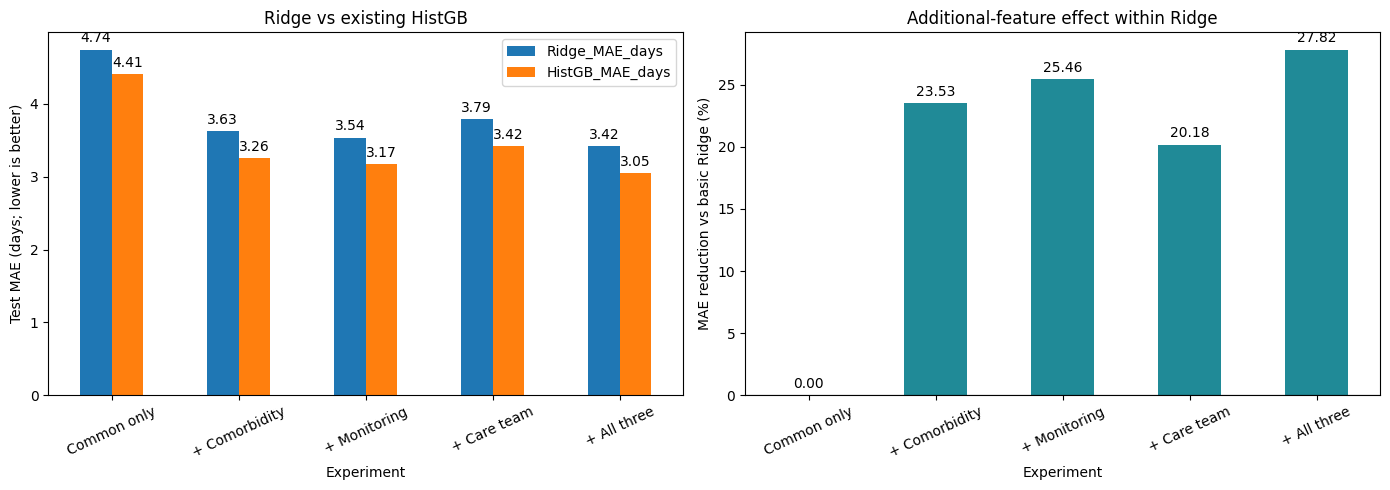

In [6]:
hgb_dir = ROOT/'Model/los_three_feature_evidence_outputs/20261015_010113_208147'
hgb = pd.read_csv(hgb_dir/'ablation.csv')
hgb_predictions = pd.read_csv(hgb_dir/'test_predictions.csv').set_index('ROW_ID')
assert hgb_predictions.index.is_unique
assert set(hgb_predictions.index) == set(predictions.ROW_ID), 'Test rows differ; do not compare.'
np.testing.assert_allclose(hgb_predictions.loc[predictions.ROW_ID,'ACTUAL_TOTAL_LOS'], predictions.Actual_LOS_days)
mapping = {'Common only':'Common only','+ Comorbidity':'COMORBIDITY_INDEX',
           '+ Monitoring':'MONITORING_HOURS','+ Care team':'CARE_TEAM_SIZE','+ All three':'All three'}
comparison = results[['Experiment','MAE_days']].rename(columns={'MAE_days':'Ridge_MAE_days'})
comparison['HistGB_MAE_days'] = [float(hgb.set_index('Experiment').loc[mapping[n],'MAE (days)']) for n in comparison.Experiment]
display(comparison)
fig, axes = plt.subplots(1,2,figsize=(14,5))
comparison.set_index('Experiment').plot.bar(ax=axes[0],rot=25)
axes[0].set(ylabel='Test MAE (days; lower is better)',title='Ridge vs existing HistGB')
results.set_index('Experiment')['MAE_reduction_percent'].plot.bar(ax=axes[1],rot=25,color='#208a97')
axes[1].axhline(0,color='black',linewidth=0.8)
axes[1].set(ylabel='MAE reduction vs basic Ridge (%)',title='Additional-feature effect within Ridge')
for ax in axes:
    for container in ax.containers:
        ax.bar_label(container,fmt='%.2f',padding=3)
fig.tight_layout()
fig.savefig(OUT/'mae_comparison.png',dpi=180,bbox_inches='tight')
plt.show()


## 6. Save reproducible results and fitted models

In [7]:
results.to_csv(OUT/'ridge_feature_comparison.csv',index=False)
comparison.to_csv(OUT/'ridge_vs_histgb.csv',index=False)
predictions.to_csv(OUT/'test_predictions.csv',index=False)
for i,(name,model) in enumerate(models.items()):
    joblib.dump(model,OUT/f'ridge_{i}.joblib')
manifest = dict(alpha=ALPHA, solver='lsqr', solver_tolerance=1e-8,
    source_validation_scope='capstone',
    numeric=NUMERIC, categorical=CATEGORICAL, feature_sets=FEATURE_SETS,
    selected_by_validation=selected, rows={s:int(m.sum()) for s,m in masks.items()},
    preprocessing_directory=str(prep_dir), baseline_manifest=baseline_manifest,
    feature_helper_sha256=base.sha256(ROOT/'Model/los_mae_optimisation.py'),
    loader_sha256=base.sha256(ROOT/'Model/los_three_feature_evidence.py'),
    hgb_results_sha256=base.sha256(hgb_dir/'ablation.csv'),
    versions=dict(python=platform.python_version(),sklearn=sklearn.__version__,numpy=np.__version__,pandas=pd.__version__),
    limitations=['Previously used test set','Extra-feature timing/provenance unconfirmed',
                 'TOTAL_LOS is defined as ADMIT_LOS + ICU_DAYS; clinical meaning unconfirmed'],
    reload_instructions='Add project Model folder to sys.path for los_mae_optimisation.add_features')
(OUT/'manifest.json').write_text(json.dumps(manifest,indent=2))
print('Saved:',OUT)


Saved: /Users/jmj3047/Library/CloudStorage/GoogleDrive-kathy.minjee.jang@gmail.com/내 드라이브/2026/하반기/UC/11522_Technology Capstone Research Project PG/Model/capstone_ridge_feature_outputs/20261021_005852_898217


## Reporting

Report actual improvements or deterioration without assuming the extra variables help.
Describe improvements as prediction-error changes, not reduced patient LOS or proven
clinical benefit. This is a follow-up experiment; do not change the chronology of prior work.
No performance result is available until this notebook is executed.
